# **Evolução e Previsão de Preços Imobiliários**


---


### Sprint 1 - Tratar e Explorar os Dados (EDA)
Objetivos desta sprint:


*   Entendimento da base e das variáveis
*   Limpeza e padronização dos dados (nulos, tipos, outiliers)
*   Análise exploratória para identificar padrões e correlações iniciais
*   Levantamento de hipóteses sobre os fatores que influenciem o preço dos imóveis






# 1. Imports e configurações

In [1]:
import warnings
import kagglehub
import numpy as np
import pandas as pd
import seaborn as sns
import importlib.metadata
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import make_column_selector, ColumnTransformer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder, StandardScaler, MinMaxScaler

warnings.filterwarnings ('ignore')

# Estilo dos gráficos
sns.set_theme(style='darkgrid', palette='muted')
plt.rcParams['figure.dpi'] = 120

#Reprodutibilidade
np.random.seed (42)

print('Bibliotecas carregadas com sucesso.')
print(f'Pandas versão: {importlib.metadata.version("pandas")}')
print(f'Matplotlib versão: {importlib.metadata.version("matplotlib")}')
print(f'Numpy versão: {importlib.metadata.version("matplotlib")}')
print(f'Seaborn versão: {importlib.metadata.version("seaborn")}')

Bibliotecas carregadas com sucesso.
Pandas versão: 2.2.3
Matplotlib versão: 3.10.0
Numpy versão: 3.10.0
Seaborn versão: 0.13.2


# 2. Carregando o Dataset

In [2]:
# Baixe o dataset em https://www.kaggle.com/datasets/omniamahmoudsaeed/real-estate-sales-2001-2022

# Baixando a última versão
path = kagglehub.dataset_download("omniamahmoudsaeed/real-estate-sales-2001-2022")

print("Caminho para o dataset:", path)

100%|██████████| 37.0M/37.0M [00:00<00:00, 168MB/s]

Extracting files...


Caminho para o dataset: /root/.cache/kagglehub/datasets/omniamahmoudsaeed/real-estate-sales-2001-2022/versions/1


In [3]:
df = pd.read_csv(f'{path}/Real_Estate_Sales_2001-2022_GL.csv')
df.head()

,Serial Number,List Year,Date Recorded,Town,Address,Assessed Value,Sale Amount,Sales Ratio,Property Type,Residential Type,Non Use Code,Assessor Remarks,OPM remarks,Location
0,2020177,2020,04/14/2021,Ansonia,323 BEAVER ST,133000.0,248400.0,0.5354,Residential,Single Family,NaN,NaN,NaN,POINT (-73.06822 41.35014)
1,2020225,2020,05/26/2021,Ansonia,152 JACKSON ST,110500.0,239900.0,0.4606,Residential,Three Family,NaN,NaN,NaN,NaN
2,2020348,2020,09/13/2021,Ansonia,230 WAKELEE AVE,150500.0,325000.0,0.4630,Commercial,NaN,NaN,NaN,NaN,NaN
3,2020090,2020,12/14/2020,Ansonia,57 PLATT ST,127400.0,202500.0,0.6291,Residential,Two Family,NaN,NaN,NaN,NaN
4,210288,2021,06/20/2022,Avon,12 BYRON DRIVE,179990.0,362500.0,0.4965,Residential,Condo,NaN,NaN,NaN,POINT (-72.879115982 41.773452988)


# 3. Limpeza e Padronização dos Dados

Etapas:


*   Remoção de duplicados
*   Tratamento de nulos
*   Correção de tipos
*   Remoção de outliers extremos




In [4]:
df_clean = df.copy()
print(f'Shape inicial: {df_clean.shape}')
print('===============================')

# 1. Duplicatas
n_dup = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates()
print(f'Número de duplicatas removidas: {n_dup}')

# 2. Extraindo mês e ano da coluna de data
if 'Date Recorded' in df_clean.columns:
    df_clean['Date Recorded'] = pd.to_datetime(df_clean['Date Recorded'])
    df_clean['Month'] = df_clean['Date Recorded'].dt.month
    df_clean['Year'] = df_clean['Date Recorded'].dt.year
    print('Colunas Year e Month extraidas com sucesso.')

# 3. SaleAmount: Remover vendas com valor zero ou negativo
if 'Sale Amount' in df_clean.columns:
    n_zero = (df_clean['Sale Amount'] <= 0).sum()
    df_clean = df_clean[df_clean['Sale Amount'] >  0]
    print(f'Número de vendas com valor zero ou negativo removidas: {n_zero}')

# 4. AssedValue: Remover valor zero ou negativo
if 'Assessed Value' in df_clean.columns:
    n_zero = (df_clean['Assessed Value'] <= 0).sum()
    df_clean = df_clean[df_clean['Assessed Value'] >  0]
    print(f'Número de avaliações com valor zero ou negativo removidas: {n_zero}')

# 5. Removendo outliers em SaleAmount
if 'Sale Amount' in df_clean.columns:
  p99 = df_clean['Sale Amount'].quantile(0.99)
  n_outlier = (df_clean['Sale Amount'] > p99).sum()
  df_clean = df_clean[df_clean['Sale Amount'] <= p99]
  print(f'Número de outliers em SaleAmount removidas: {n_outlier}')

# 6. Substituindo nulos por 'Desconhecido' em Residential Type
if 'Residential Type' in df_clean.columns:
  n_nulos = df_clean['Residential Type'].isnull().sum()
  df_clean['Residential Type'] = df_clean['Residential Type'].fillna('Desconhecido')
  print(f'Número de nulos em Residential Type substituídos por "Desconhecido": {n_nulos}')

# 7. Padronizar nomes de colunas
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(' ', '_')
)

print(f'===============================')
print(f'Shape final: {df_clean.shape}')
print(f'Registros removidos no total: {df.shape[0] - df_clean.shape[0]}')

Shape inicial: (1097629, 14)
Número de duplicatas removidas: 0
Colunas Year e Month extraidas com sucesso.
Número de vendas com valor zero ou negativo removidas: 1810
Número de avaliações com valor zero ou negativo removidas: 6902
Número de outliers em SaleAmount removidas: 10864
Número de nulos em Residential Type substituídos por "Desconhecido": 386540
Shape final: (1078053, 16)
Registros removidos no total: 19576


# 4. Análise Exploratória dos Dados (EDA)

In [5]:
df_clean['residential_type'] = df_clean['residential_type'].replace({'Single Family':0, 'Condo': 1, 'Two Family':2, 'Three Family': 3, 'Four Family': 4, 'Desconhecido': 5})
df_clean.head()

,serial_number,list_year,date_recorded,town,address,assessed_value,sale_amount,sales_ratio,property_type,residential_type,non_use_code,assessor_remarks,opm_remarks,location,month,year
0,2020177,2020,2021-04-14,Ansonia,323 BEAVER ST,133000.0,248400.0,0.5354,Residential,0,NaN,NaN,NaN,POINT (-73.06822 41.35014),4.0,2021.0
1,2020225,2020,2021-05-26,Ansonia,152 JACKSON ST,110500.0,239900.0,0.4606,Residential,3,NaN,NaN,NaN,NaN,5.0,2021.0
2,2020348,2020,2021-09-13,Ansonia,230 WAKELEE AVE,150500.0,325000.0,0.4630,Commercial,5,NaN,NaN,NaN,NaN,9.0,2021.0
3,2020090,2020,2020-12-14,Ansonia,57 PLATT ST,127400.0,202500.0,0.6291,Residential,2,NaN,NaN,NaN,NaN,12.0,2020.0
4,210288,2021,2022-06-20,Avon,12 BYRON DRIVE,179990.0,362500.0,0.4965,Residential,1,NaN,NaN,NaN,POINT (-72.879115982 41.773452988),6.0,2022.0


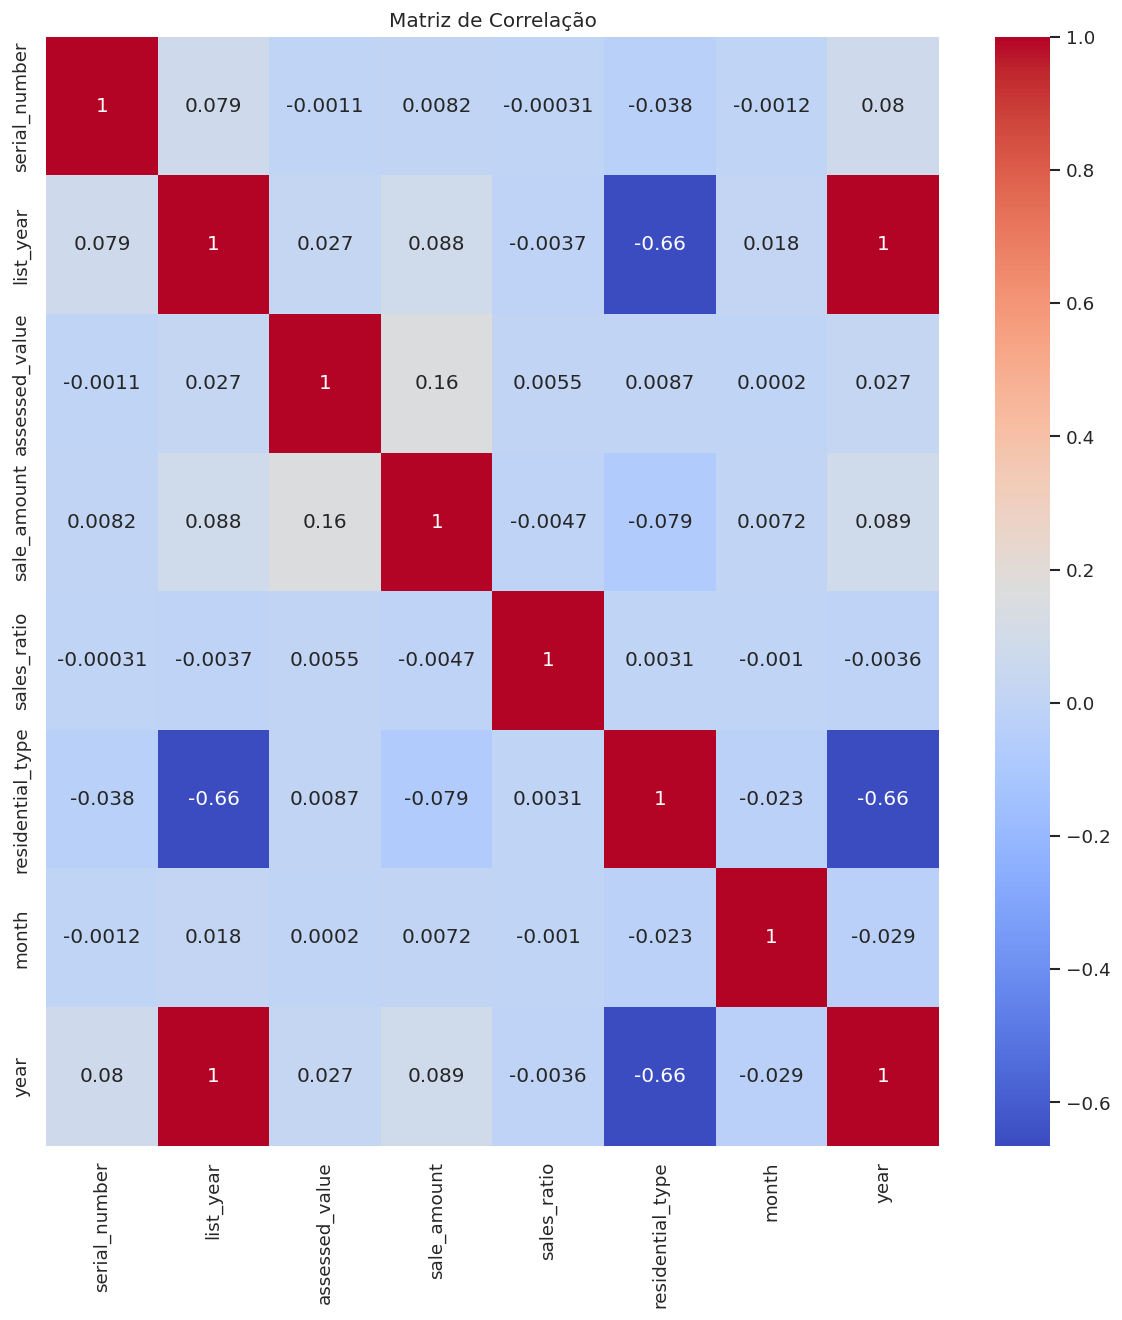

In [6]:
plt.figure(figsize=(12, 12))
# Select only numerical features for correlation calculation
numerical_df = df_clean.select_dtypes(include=['number'])  # This line is new
df_corr = numerical_df.corr() # Changed to numerical_df from df
sns.heatmap(df_corr, annot=True, cmap='coolwarm')
plt.title('Matriz de Correlação')
plt.show()

In [7]:
df_clean.dtypes
df_clean.head()

,serial_number,list_year,date_recorded,town,address,assessed_value,sale_amount,sales_ratio,property_type,residential_type,non_use_code,assessor_remarks,opm_remarks,location,month,year
0,2020177,2020,2021-04-14,Ansonia,323 BEAVER ST,133000.0,248400.0,0.5354,Residential,0,NaN,NaN,NaN,POINT (-73.06822 41.35014),4.0,2021.0
1,2020225,2020,2021-05-26,Ansonia,152 JACKSON ST,110500.0,239900.0,0.4606,Residential,3,NaN,NaN,NaN,NaN,5.0,2021.0
2,2020348,2020,2021-09-13,Ansonia,230 WAKELEE AVE,150500.0,325000.0,0.4630,Commercial,5,NaN,NaN,NaN,NaN,9.0,2021.0
3,2020090,2020,2020-12-14,Ansonia,57 PLATT ST,127400.0,202500.0,0.6291,Residential,2,NaN,NaN,NaN,NaN,12.0,2020.0
4,210288,2021,2022-06-20,Avon,12 BYRON DRIVE,179990.0,362500.0,0.4965,Residential,1,NaN,NaN,NaN,POINT (-72.879115982 41.773452988),6.0,2022.0


In [8]:
propriedade = df_clean["property_type"].value_counts()
propriedade

,count
property_type,
Single Family,397322
Residential,149172
Condo,103935
Two Family,26362
Three Family,12583
Vacant Land,7660
Commercial,5404
Four Family,2139
Apartments,1080


In [9]:
residencial = df_clean["residential_type"].value_counts()
residencial

,count
residential_type,
0,502194
5,386540
1,135019
2,34791
3,16562
4,2947


In [10]:
list = df_clean["list_year"].value_counts()
list

,count
list_year,
2004,81667
2020,65449
2003,62866
2005,59988
2001,58514
2002,58485
2019,58262
2021,56025
2018,50028


In [11]:
year = df_clean["year"].value_counts()
year

,count
year,
2005.0,77271
2004.0,72242
2021.0,63325
2020.0,61739
2002.0,59208
2006.0,55854
2003.0,55151
2019.0,51962
2022.0,51836


In [12]:
df_clean['residential_type'] = df_clean['residential_type'].replace({'Single Family':0, 'Condo': 1, 'Two Family':2, 'Three Family': 3, 'Four Family': 4})
df_clean.head()

,serial_number,list_year,date_recorded,town,address,assessed_value,sale_amount,sales_ratio,property_type,residential_type,non_use_code,assessor_remarks,opm_remarks,location,month,year
0,2020177,2020,2021-04-14,Ansonia,323 BEAVER ST,133000.0,248400.0,0.5354,Residential,0,NaN,NaN,NaN,POINT (-73.06822 41.35014),4.0,2021.0
1,2020225,2020,2021-05-26,Ansonia,152 JACKSON ST,110500.0,239900.0,0.4606,Residential,3,NaN,NaN,NaN,NaN,5.0,2021.0
2,2020348,2020,2021-09-13,Ansonia,230 WAKELEE AVE,150500.0,325000.0,0.4630,Commercial,5,NaN,NaN,NaN,NaN,9.0,2021.0
3,2020090,2020,2020-12-14,Ansonia,57 PLATT ST,127400.0,202500.0,0.6291,Residential,2,NaN,NaN,NaN,NaN,12.0,2020.0
4,210288,2021,2022-06-20,Avon,12 BYRON DRIVE,179990.0,362500.0,0.4965,Residential,1,NaN,NaN,NaN,POINT (-72.879115982 41.773452988),6.0,2022.0


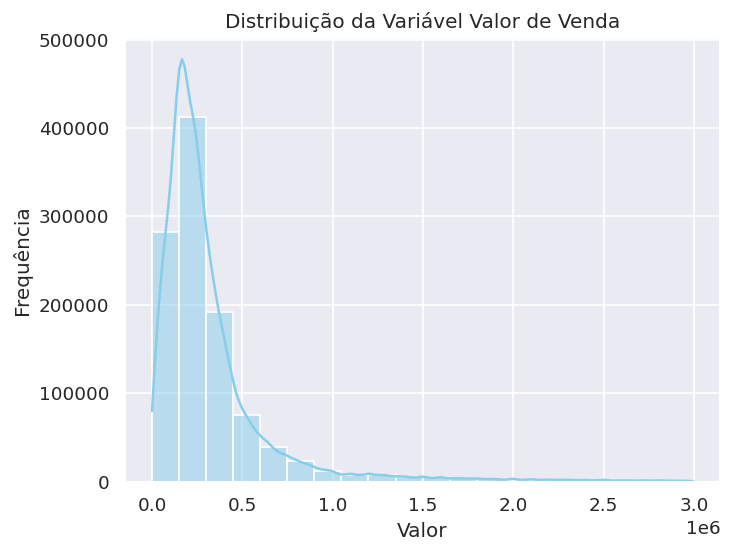

In [13]:

sns.histplot(data=df_clean, x='sale_amount', bins=20, kde=True, color='skyblue')

plt.title(f'Distribuição da Variável Valor de Venda')
plt.xlabel('Valor')
plt.ylabel('Frequência')
plt.show()

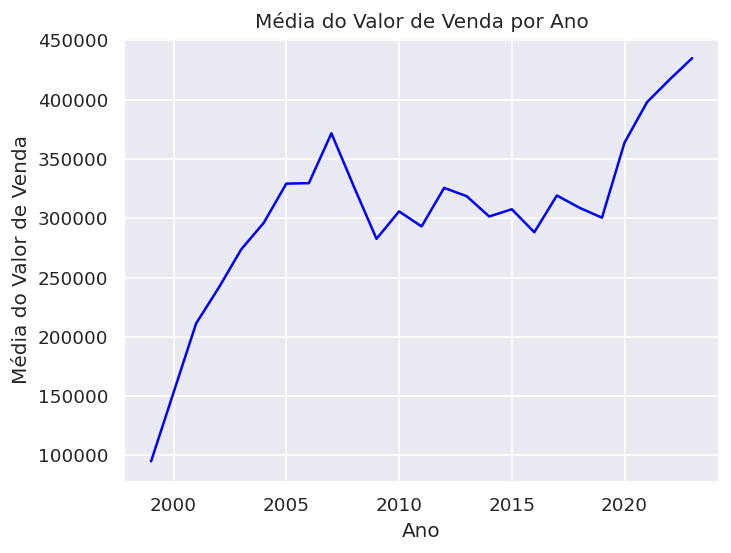

In [14]:
sns.lineplot(data=df_clean, x='year', y='sale_amount', estimator='mean', errorbar=None, color='blue')
plt.title('Média do Valor de Venda por Ano')
plt.xlabel('Ano')
plt.ylabel('Média do Valor de Venda')
plt.show()

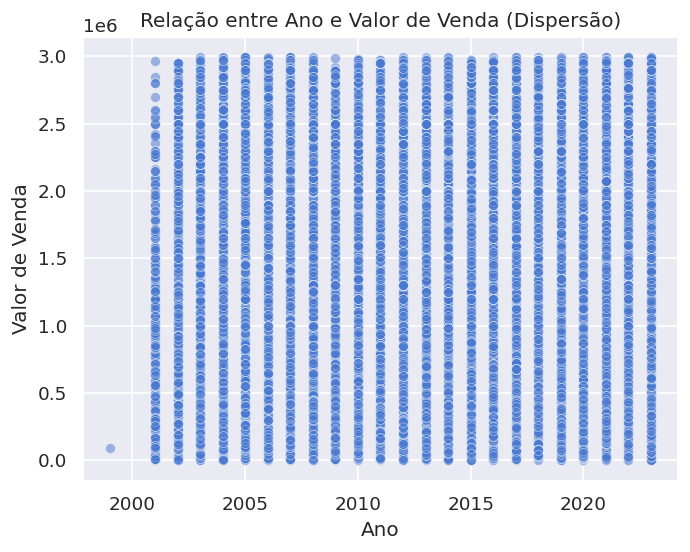

In [15]:
sns.scatterplot(data=df_clean, x='year', y='sale_amount', alpha=0.5)
plt.title('Relação entre Ano e Valor de Venda (Dispersão)')
plt.xlabel('Ano')
plt.ylabel('Valor de Venda')
plt.show()

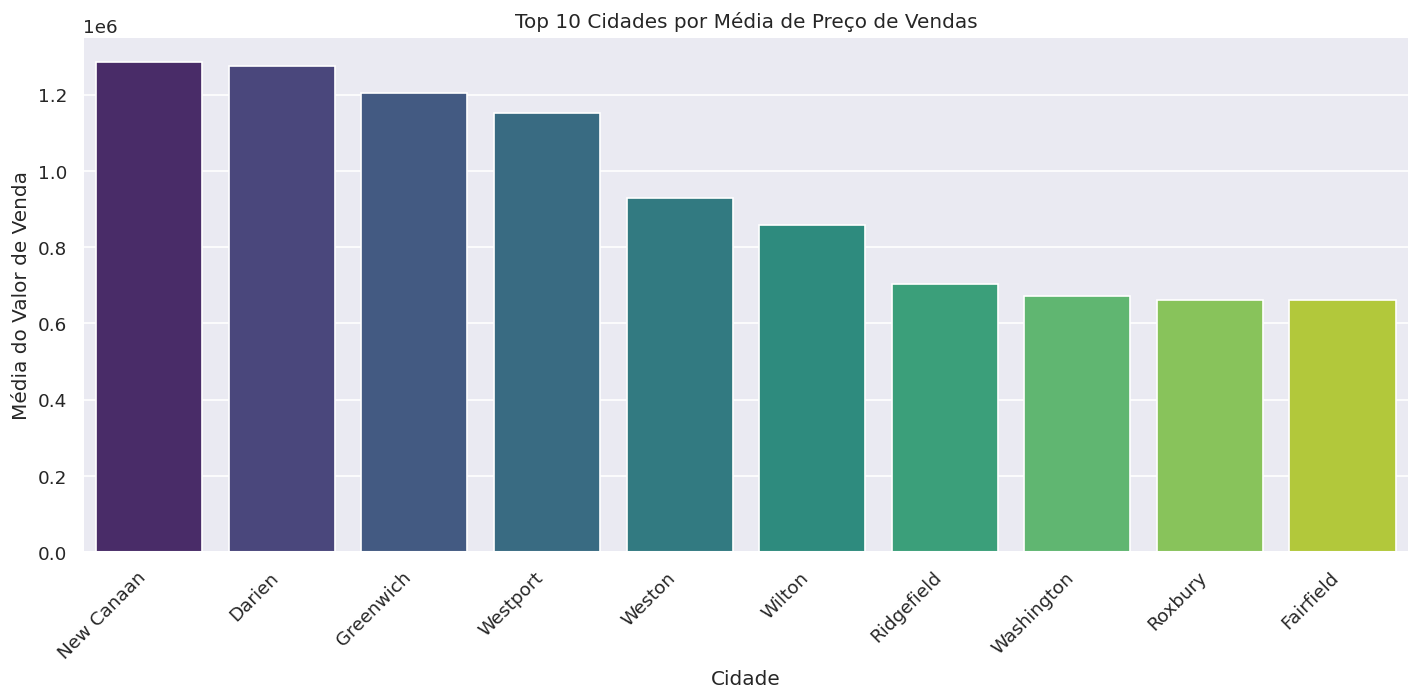

In [16]:
sales_by_town = df_clean.groupby('town')['sale_amount'].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x=sales_by_town.head(10).index, y=sales_by_town.head(10).values, palette='viridis')
plt.title('Top 10 Cidades por Média de Preço de Vendas')
plt.xlabel('Cidade')
plt.ylabel('Média do Valor de Venda')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

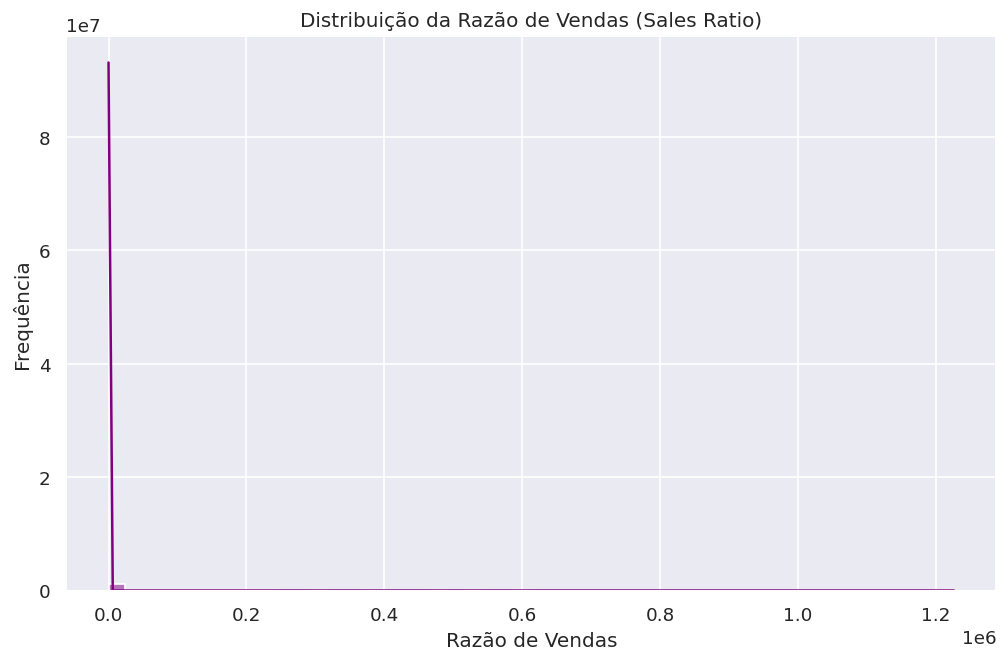

In [17]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df_clean, x='sales_ratio', bins=50, kde=True, color='purple')
plt.title('Distribuição da Razão de Vendas (Sales Ratio)')
plt.xlabel('Razão de Vendas')
plt.ylabel('Frequência')
plt.grid(True)
plt.show()

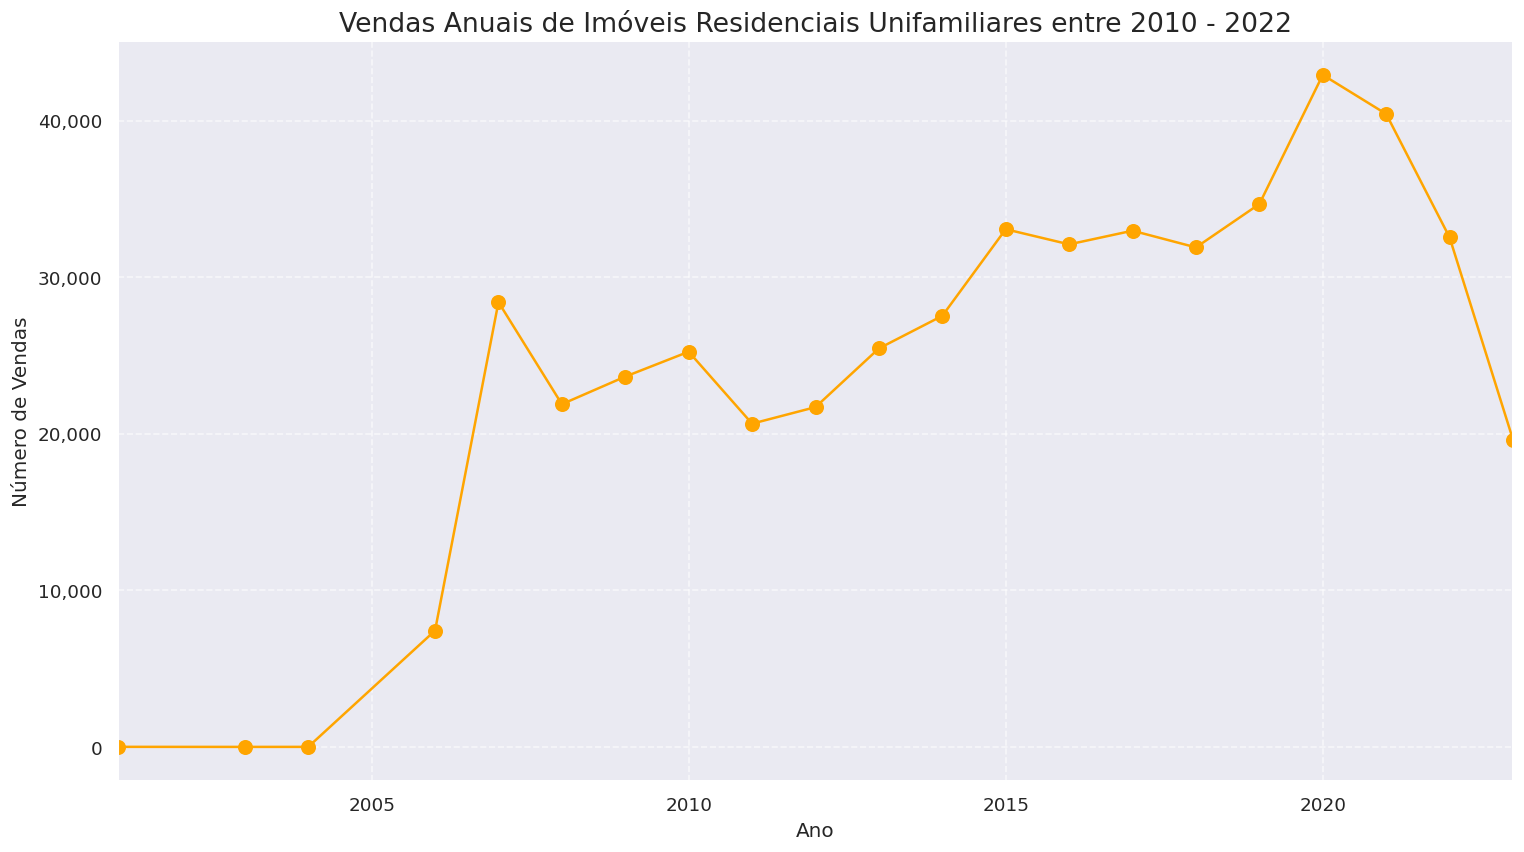

date_recorded
2001         $2,402,711
2003           $158,900
2004         $1,949,900
2006     $2,838,127,603
2007    $12,032,420,928
2008     $7,910,555,044
2009     $7,444,012,040
2010     $8,856,871,933
2011     $6,759,508,260
2012     $7,995,446,584
2013     $9,023,105,297
2014     $9,106,043,866
2015    $11,120,462,355
2016    $10,004,796,598
2017    $11,502,489,127
2018    $10,632,696,614
2019    $11,240,592,582
2020    $17,426,185,893
2021    $18,052,878,322
2022    $15,275,308,431
2023     $9,500,653,954
Name: sale_amount, dtype: object


In [18]:
import matplotlib.ticker as mticker

# Filtrar para imóveis residenciais unifamiliares (Single Family)
df_single_family = df_clean[df_clean['residential_type'] == 0].copy()

yearly_sales_count = df_single_family.groupby(df_single_family['date_recorded'].dt.to_period('Y')).size()

plt.figure(figsize=(15, 8))
yearly_sales_count.plot(kind = 'line', color = 'orange', marker = 'o', markersize = 8)
ax = plt.gca()
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, p: f'{x:,.0f}'))
plt.title('Vendas Anuais de Imóveis Residenciais Unifamiliares entre 2010 - 2022', fontsize = 16)
plt.xlabel('Ano')
plt.ylabel('Número de Vendas')
plt.grid(True, linestyle = '--', alpha = 0.6)
plt.show()

yearly_sales = df_single_family.groupby(df_single_family['date_recorded'].dt.year)['sale_amount'].sum()
yearly_sales_int = yearly_sales.astype('int64')
formatted_sales = yearly_sales.apply(lambda x: f"${x:,.0f}")
print(formatted_sales)

# Sprint 2 - Preparação para modelagem
Objetivos desta sprint:


*   Carregar o dataset limpo gerado na Sprint 1
*   Converter todas as colunas categoricas em numéricas (encoding)
*   Normalizar todas as colunas numéricas

# 5. Remoção de colunas inúteis para o modelo

In [19]:
# Colunas a descartar (não agregam valor preditivo)
COLS_TO_DROP = [
    'serial_number', 'date_recorded', 'address',
    'assessor_remarks', 'opm_remarks', 'location'
]

df_model = df_clean.drop(columns=COLS_TO_DROP)
print(f'Colunas removidas: {COLS_TO_DROP}')
print(f'Colunas restantes: {df_model.columns.tolist()}')


Colunas removidas: ['serial_number', 'date_recorded', 'address', 'assessor_remarks', 'opm_remarks', 'location']
Colunas restantes: ['list_year', 'town', 'assessed_value', 'sale_amount', 'sales_ratio', 'property_type', 'residential_type', 'non_use_code', 'month', 'year']


# 6. Encoding de Colunas Categóricas

O `Ordinal Encoder` converte cada valor único da coluna em um inteiro (0, 1, 2, 3)

In [20]:
categorical_cols = df_model.select_dtypes(include=['object']).columns.tolist()
print(f'Colunas para OrdinalEconder: {categorical_cols}')

df_encoded = df_model.copy()

ord_encoder = OrdinalEncoder(
    handle_unknown='use_encoded_value',
    unknown_value=-1
)

df_encoded[categorical_cols] = ord_encoder.fit_transform(
    df_encoded[categorical_cols].astype(str)
)

print('\nEncoding aplicado. Amostra:')
display(df_encoded[categorical_cols].head())
print(f'\nColunas object restantes: {df_encoded.select_dtypes(include=["object"]).columns.tolist()}')

Colunas para OrdinalEconder: ['town', 'property_type', 'non_use_code']

Encoding aplicado. Amostra:


,town,property_type,non_use_code
0,2.0,6.0,106.0
1,2.0,6.0,106.0
2,2.0,1.0,106.0
3,2.0,6.0,106.0
4,4.0,6.0,106.0



Colunas object restantes: []


# 7. Normalização de Features Numéricas (StandardScaler)

O `Standard Scaler` transforma cada coluna para ter media 0 e desvio padrão 1:

$$
x_{scaled} = \frac{x - μ}{σ}
$$

In [21]:
TARGET_COL = 'sale_amount'
df_encoded.head()

y = df_encoded[TARGET_COL].copy()
X = df_encoded.drop(columns=TARGET_COL)

scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns,
    index=X.index
)

df_final = X_scaled.copy()
df_final[TARGET_COL] = y.values

print('Verificação após StandardScaler:')
display(X_scaled.describe().loc[['mean', 'std']].round(2))

Verificação após StandardScaler:


,list_year,town,assessed_value,sales_ratio,property_type,residential_type,non_use_code,month,year
mean,0.0,-0.0,-0.0,0.0,0.0,0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [22]:
display(df_final)

,list_year,town,assessed_value,sales_ratio,property_type,residential_type,non_use_code,month,year,sale_amount
0,1.294260,-1.844067,-0.092738,-0.005081,-0.639152,-0.890969,0.553008,-0.867803,1.330348,248400.0
1,1.294260,-1.844067,-0.111305,-0.005122,-0.639152,0.419550,0.553008,-0.559835,1.330348,239900.0
2,1.294260,-1.844067,-0.078297,-0.005121,-2.420805,1.293229,0.553008,0.672040,1.330348,325000.0
3,1.294260,-1.844067,-0.097359,-0.005030,-0.639152,-0.017290,0.553008,1.595946,1.182733,202500.0
4,1.441995,-1.802004,-0.053961,-0.005102,-0.639152,-0.454130,0.553008,-0.251866,1.477963,362500.0
...,...,...,...,...,...,...,...,...,...,...
1097624,1.589730,0.953085,0.196401,-0.005068,-0.639152,-0.890969,0.553008,0.980009,1.477963,865000.0
1097625,1.589730,1.457835,-0.185451,-0.005361,-0.639152,-0.890969,-2.331387,0.672040,1.625578,760857.0
1097626,1.589730,0.953085,-0.092820,-0.005043,-0.639152,-0.454130,0.553008,-1.791709,1.625578,220000.0
1097627,1.589730,0.343180,0.704750,-0.004992,-0.639152,-0.890969,0.553008,0.672040,1.625578,1575000.0


# 8. Dividir os dados em Treino e Teste para o modelo

In [23]:
# Separando em atributos e respostas para treino e teste

atributos_treino, atributos_teste, respostas_treino, respostas_teste = train_test_split(X, y, test_size = 0.25, random_state = 42)

In [24]:
modelo = {
    'Decision Tree': DecisionTreeRegressor(max_depth=10, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=20, max_depth=10, random_state=42),
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0)
}

resultados = {}

for nome_modelo, modelo in modelo.items():
    modelo.fit(atributos_treino, respostas_treino)
    predicoes = modelo.predict(atributos_teste)

    mae = mean_absolute_error(respostas_teste, predicoes)
    rmse = mean_squared_error(respostas_teste, predicoes)

    resultados[nome_modelo] = {'MAE': mae, 'RMSE': rmse}
    print(f'\n{nome_modelo}')
    print(f'MAE: {mae}')
    print(f'RMSE: {rmse}')


Decision Tree
MAE: 14431.751529665276
RMSE: 910454624.8323163

Random Forest
MAE: 8780.850911897187
RMSE: 438379961.3222687

Linear Regression
MAE: 194606.9741373897
RMSE: 106990562493.22137

Ridge
MAE: 194606.97480989166
RMSE: 106990563317.71785


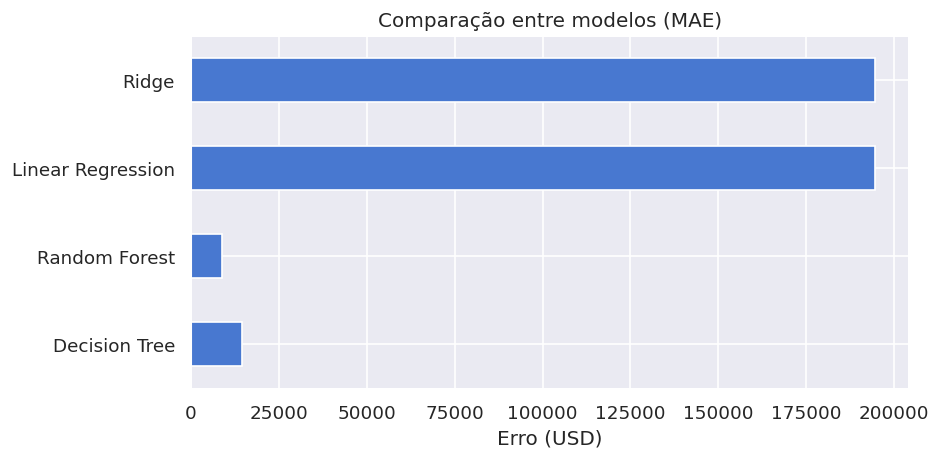

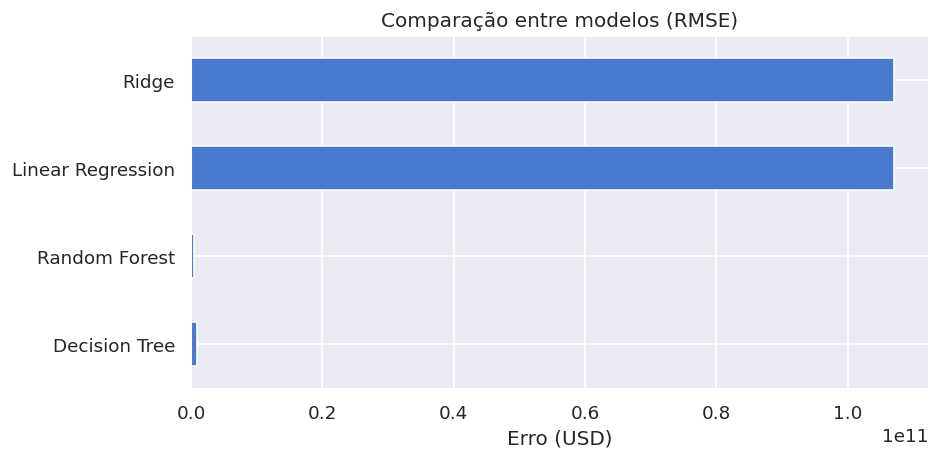

In [25]:
df_resultados = pd.DataFrame(resultados).T

df_resultados['MAE'].plot.barh(figsize=(8,4))
plt.xlabel('Erro (USD)')
plt.title('Comparação entre modelos (MAE)')
plt.tight_layout()
plt.show()

df_resultados['RMSE'].plot.barh(figsize=(8,4))
plt.xlabel('Erro (USD)')
plt.title('Comparação entre modelos (RMSE)')
plt.tight_layout()
plt.show()